In [2]:
import sqlite3
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DB = next(p for p in [Path("../data/carepulse.db"), Path("data/carepulse.db")] if p.exists())
con = sqlite3.connect(DB)
df = pd.read_sql("SELECT * FROM mart_fct_index_discharges", con)

In [3]:
print(df.shape)

(7937, 20)


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7937 entries, 0 to 7936
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   index_encounter_id          7937 non-null   str    
 1   patient_id                  7937 non-null   str    
 2   department                  7937 non-null   str    
 3   year_month                  7937 non-null   str    
 4   encounter_day               7937 non-null   int64  
 5   discharge_day               7937 non-null   float64
 6   length_of_stay_days         7937 non-null   int64  
 7   total_cost                  7937 non-null   float64
 8   admission_source            7937 non-null   str    
 9   discharge_disposition       7937 non-null   str    
 10  age                         7937 non-null   int64  
 11  gender                      7937 non-null   str    
 12  age_band                    7937 non-null   str    
 13  payer_type                  7937 non-null   

In [5]:
df.head()

,index_encounter_id,patient_id,department,year_month,encounter_day,discharge_day,length_of_stay_days,total_cost,admission_source,discharge_disposition,age,gender,age_band,payer_type,chronic_conditions,prior_inpatient_admissions,is_readmission_30d,gap_days,readmission_encounter_id,readmission_cost
0,ENC-0023497,PAT-002854,Nephrology,2023-01,19358,19359.0,1,87109.86,OPD,Skilled Nursing,33,Male,30-44,Private,2,0,1,15.0,ENC-0023498,126172.65
1,ENC-0014275,PAT-001746,General Medicine,2023-01,19360,19361.0,1,18555.57,Transfer,Home,51,Male,45-59,Government,0,0,0,158.0,ENC-0014276,0.00
2,ENC-0013616,PAT-001669,Neurology,2023-01,19362,19363.0,1,94329.32,Physician Referral,Home,27,Female,18-29,Self-pay,3,0,0,1172.0,ENC-0013619,0.00
3,ENC-0001369,PAT-000173,Gastroenterology,2023-01,19360,19364.0,4,71904.39,Emergency Room,Skilled Nursing,74,Female,60-74,Self-pay,0,0,0,245.0,ENC-0001371,0.00
4,ENC-0014796,PAT-001807,Orthopedics,2023-01,19361,19364.0,3,145256.47,Emergency Room,Home with Home Health,62,Male,60-74,Government,0,0,0,186.0,ENC-0014797,0.00


In [8]:
print("Eligible discharges:", len(df))
print("Readmissions      :", int(df["is_readmission_30d"].sum()))
print("Readmission rate % :", round(df["is_readmission_30d"].mean() * 100, 2))

Eligible discharges: 7937
Readmissions      : 1115
Readmission rate % : 14.05


In [9]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
encounter_day,7937.0,20031.70,342.37,19358.00,19740.00,20037.00,20331.00,20612.00
discharge_day,7937.0,20035.39,342.37,19359.00,19743.00,20041.00,20334.00,20613.00
length_of_stay_days,7937.0,3.70,2.75,1.00,1.00,3.00,5.00,20.00
total_cost,7937.0,94524.36,74196.79,14139.64,32927.06,80109.51,126751.40,549530.67
age,7937.0,52.99,16.71,16.00,41.00,53.00,64.00,95.00
chronic_conditions,7937.0,6.85,5.98,0.00,3.00,5.00,9.00,46.00
prior_inpatient_admissions,7937.0,1.84,2.06,0.00,0.00,1.00,3.00,14.00
is_readmission_30d,7937.0,0.14,0.35,0.00,0.00,0.00,0.00,1.00
gap_days,5518.0,220.26,221.16,3.00,45.00,147.50,325.75,1230.00
readmission_cost,7937.0,13193.66,43440.87,0.00,0.00,0.00,0.00,517428.64


In [10]:
df.isna().sum()[lambda s: s > 0]

gap_days                    2419
readmission_encounter_id    2419
dtype: int64

## 30-day readmission by age band

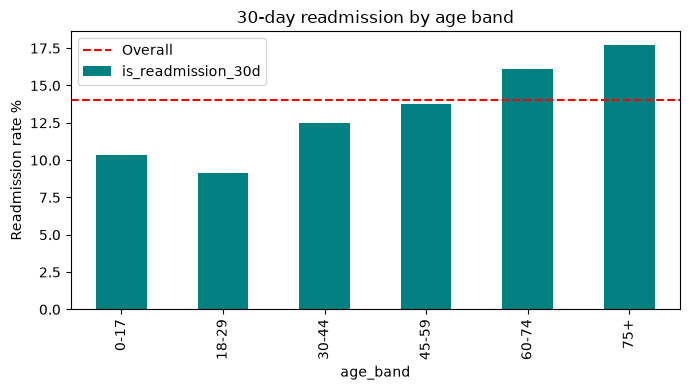

In [13]:
order = ["0-17", "18-29", "30-44", "45-59", "60-74", "75+", "Unknown"]
rate = (df.groupby("age_band")["is_readmission_30d"].mean()*100)
rate = rate.reindex([o for o in order if o in rate.index])
ax = rate.plot(kind="bar",color="teal",figsize=(7, 4))
ax.axhline(df["is_readmission_30d"].mean() * 100,color="red",ls="--",label="Overall")
ax.set_ylabel("Readmission rate %")
ax.set_title("30-day readmission by age band")
ax.legend()
plt.tight_layout()
plt.show()

In [14]:
print(rate.round(2))

age_band
0-17     10.34
18-29     9.11
30-44    12.46
45-59    13.79
60-74    16.12
75+      17.74
Name: is_readmission_30d, dtype: float64


#### Elderly Care Focus 
* **Age-driven upward trend:** From the 18-29 age group (**9.11%**), the 30-day readmission rate rises steadily across every older bracket to **17.74%** in the 75+ group.
* **Above-average risk in older adults** Both 60-74 (**16.12%**) and 75+ (**17.74%**) sit noticeably above the overall readmission baseline (~14%), whereas 0-17 (**10.34%**), 18-29 (**9.11%**), 30-44 (**12.46%**), and 45-59 (**13.79%**) remain below or around average.
* **Actionable takeaway:** Post-discharge follow-ups, medication adherence checks, and care transition planning should prioritize patients aged 60+ (especially 75+) to help reduce avoidable 30-day readmissions.

## Department-Wise Readmission

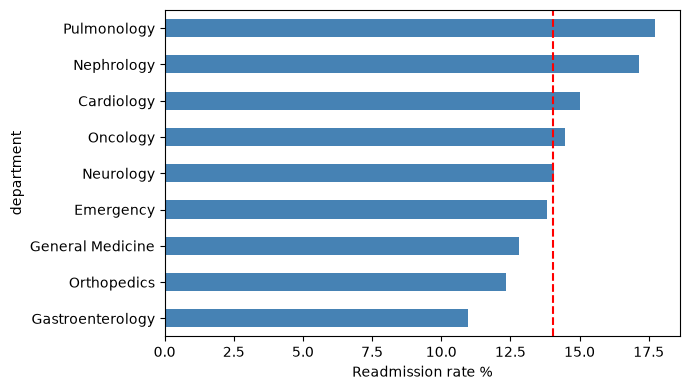

In [16]:
dept = (df.groupby("department")["is_readmission_30d"].mean() * 100).sort_values()
ax = dept.plot(kind="barh",color="steelblue",figsize=(7, 4))
ax.axvline(df["is_readmission_30d"].mean()*100,color="red",ls="--")
ax.set_xlabel("Readmission rate %")
plt.tight_layout()
plt.show()

### Department-Wise Readmission Insights
* **Highest Risk Departments:** **Pulmonology** (~17.5%) and **Nephrology** (~17%) show the highest 30-day readmission rates, sitting well above the overall average (~14%).
* **Above-Average Risk:** **Cardiology** and **Oncology** also exceed the overall baseline, indicating higher readmission vulnerability among patients with chronic respiratory, renal, cardiac, and oncological conditions.
* **Lowest Risk Departments:** **Gastroenterology** (~11%), **Orthopedics** (~12.2%), and **General Medicine** (~12.7%) maintain the lowest readmission rates, well below the hospital-wide average.
* **Actionable Takeaway:** Discharge planning and post-discharge monitoring protocols should prioritize high-risk specialty units—particularly **Pulmonology** and **Nephrology**—to reduce preventable readmissions.

## Prior Admissions & Chronic Conditions

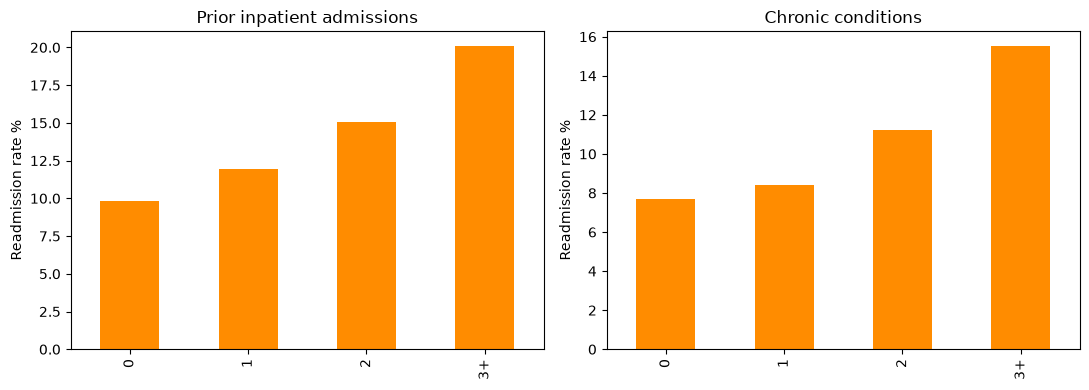

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, title in [(axes[0], "prior_inpatient_admissions", "Prior inpatient admissions"),
                       (axes[1], "chronic_conditions", "Chronic conditions")]:
    s = df.assign(seg=df[col].clip(upper=3).map(lambda v: "3+" if v >= 3 else str(int(v))))
    (s.groupby("seg")["is_readmission_30d"].mean() * 100).plot(kind="bar", ax=ax, color="darkorange")
    ax.set_title(title); ax.set_ylabel("Readmission rate %")
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

### Prior Admissions & Chronic Conditions Insights
* **Sharp Rise with Prior Admissions:** 30-day readmission rates more than double as prior inpatient admissions increase—rising steadily from **~9.8%** (0 admissions) and **~12.0%** (1) to **~15.2%** (2) and **>20%** (3+ admissions).
* **Strong Escalation with Chronic Conditions:** Patients with 0 or 1 chronic condition have relatively low readmission rates (**~7.7%** and **~8.5%**), whereas rates jump noticeably to **~11.3%** for 2 conditions and **~15.8%** for 3+ conditions.
* **Actionable Takeaway:** Patients with **2+ prior inpatient admissions** or **2+ chronic conditions** (especially those in the **3+** tier) form a critical high-risk cohort that should be flagged at discharge for intensive care coordination and early follow-up.

## Length of stay (LOS)

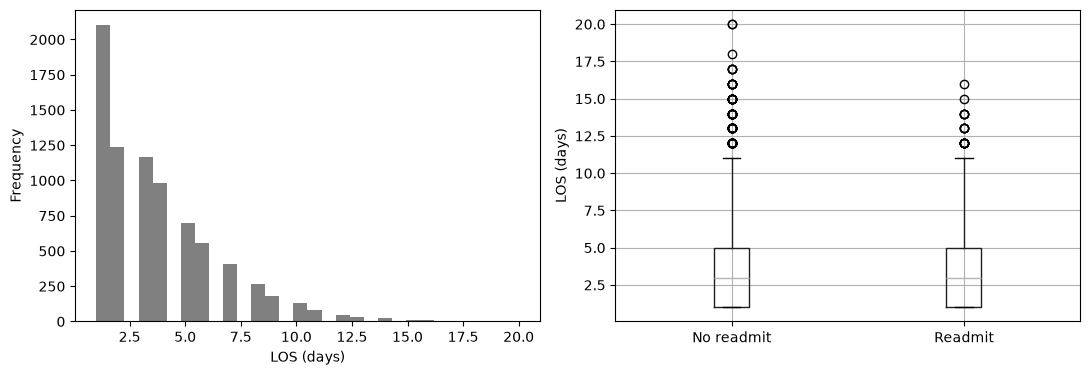

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
df["length_of_stay_days"].plot(kind="hist", bins=30, ax=axes[0], color="gray")
axes[0].set_xlabel("LOS (days)")
df.assign(re=df["is_readmission_30d"].map({0: "No readmit", 1: "Readmit"})).boxplot(
    column="length_of_stay_days", by="re", ax=axes[1])
axes[1].set_title(""); axes[1].set_xlabel(""); axes[1].set_ylabel("LOS (days)")
plt.suptitle(""); plt.tight_layout(); plt.show()

### Length of Stay (LOS) Insights
* **Right-Skewed Distribution:** Hospital length of stay is heavily right-skewed, with most patients staying between **1 and 5 days** and a long tail extending up to **20 days**.
* **Minimal Difference Across Readmission Groups:** Both No readmit and Readmit groups share nearly identical medians (~**3 days**) and interquartile ranges (~**2–5 days**), along with upper-tail outliers beyond **11 days**.
* **Actionable Takeaway:** On its own, length of stay shows little separation between readmitted and non-readmitted patients, suggesting it should be analyzed in combination with **age band**, **department**, or **comorbidities** rather than used as a standalone risk indicator.

## Correlation heatmap

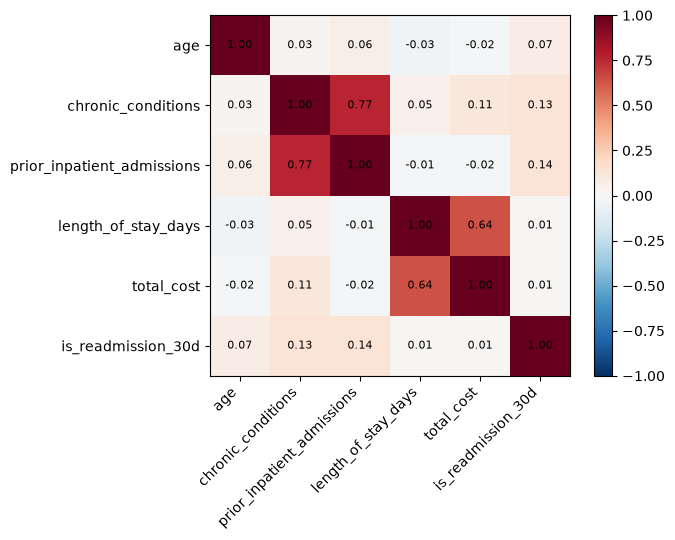

In [7]:
cols = ["age", "chronic_conditions", "prior_inpatient_admissions",
        "length_of_stay_days", "total_cost", "is_readmission_30d"]
corr = df[cols].corr()
fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=45, ha="right")
ax.set_yticks(range(len(cols))); ax.set_yticklabels(cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im)
plt.tight_layout()
plt.show()

### Correlation Matrix Insights
* **Strongest Feature Relationships:** **chronic_conditions** and **prior_inpatient_admissions** show the strongest positive correlation (**r = 0.77**), followed by **length_of_stay_days** and **total_cost** (**r = 0.64**), reflecting higher hospital utilization and costs for longer stays.
* **Key Drivers of 30-Day Readmission:** Among numeric variables, **prior_inpatient_admissions** (**r = 0.14**) and **chronic_conditions** (**r = 0.13**) have the strongest positive correlation with **is_readmission_30d**, followed by **age (r = 0.07)**.
* **Negligible Linear Impact of LOS & Cost:** Both **length_of_stay_days (r = 0.01)** and **total_cost (r = 0.01)** show virtually no linear relationship with 30-day readmission, confirming earlier distributional findings.
* **Actionable Takeaway:** Patients with multiple chronic conditions and a history of prior inpatient admissions represent the primary high-risk group for readmission, while feature engineering or non-linear models may be needed to capture deeper interaction